## Çok sınıflı sınıflandırma (Multiclass classification)

* Önceki görevde ikili (binary) bir sınıflandırma problemini çözdük.  
* Peki ya **çok sınıflı (multiclass) bir sınıflandırma problemi**?

🎯 Egzersizin Amaçları:
- Çok sınıflı bir sınıflandırma problemi için tasarlanmış bir Sinir Ağı (Neural Network) yazmak
- Bu modelin ne kadar kolay **overfit** olabileceğini gözlemlemek… !

## (1) Bir `Blobs` veri kümesi oluşturun

📚 Sklearn’deki **`make_blobs`** fonksiyonu [(dokümantasyona bakınız)](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html) aşağıdakileri üretmenize olanak tanır:
- İstenilen sayıda veri örneği (`n_samples` parametresi)
- Her veri örneği için istenilen sayıda özellik (`n_features` parametresi)
- İstenilen sayıda sınıf/kategori (`centers` parametresi)
- Sınıflar arasındaki mesafe (`cluster_std` parametresi)

💡 Ayrıca, verinin **deterministik** olarak (aynı şekilde) üretilmesini ve tekrar edilebilir olmasını sağlayan `random_state` parametresi de vardır.


❓ Belgelere göre:

👽 Aşağıdakilerle bir ***blobs*** veri kümesi oluşturun:
- 1200 örnek
- Örnek başına 8 özellik
- 7 veri kategorisi
- Kategoriler arasındaki mesafe 8

🔮 1'e eşit bir `random_state` seçin.

📏 Şekli yazdırın ve `X` için (1200, 8) ve `y` için (1200,) ile eşleştiğini kontrol edin ❓

In [1]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt

X, y = make_blobs(
    n_samples=1200,
    n_features=8,
    centers=7,
    cluster_std=8,
    random_state=1
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Sınıflar:", np.unique(y))

X shape: (1200, 8)
y shape: (1200,)
Sınıflar: [0 1 2 3 4 5 6]


❓ _matplotlib_ kullanarak bu blob veri kümesinin iki (rastgele) boyutunun dağılım grafiğini çizin. Her nokta, ait olduğu kategoriye göre renklendirilmelidir. ❓

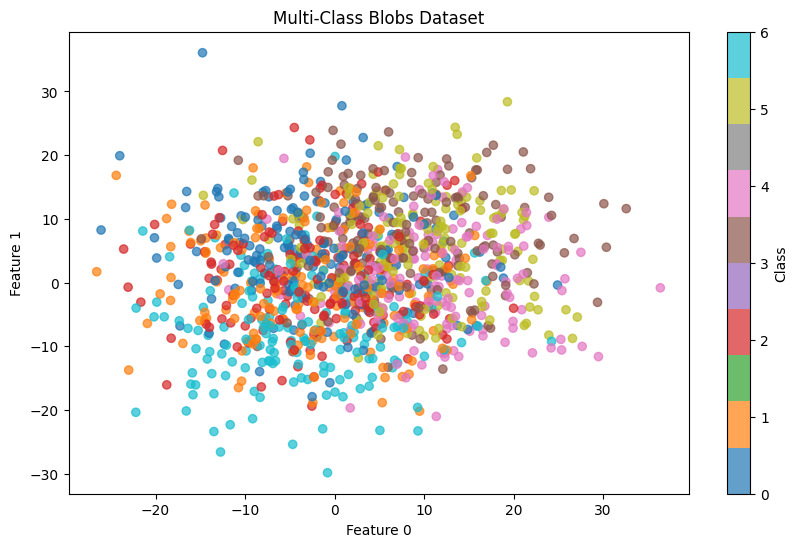

In [2]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title("Multi-Class Blobs Dataset")
plt.colorbar(label="Class")
plt.show()

❓ Diğer boyutlarda da aynı işlemi tekrarlayın. Veri noktalarının kolayca ayrılmadığını görsel olarak görebilirsiniz ❓

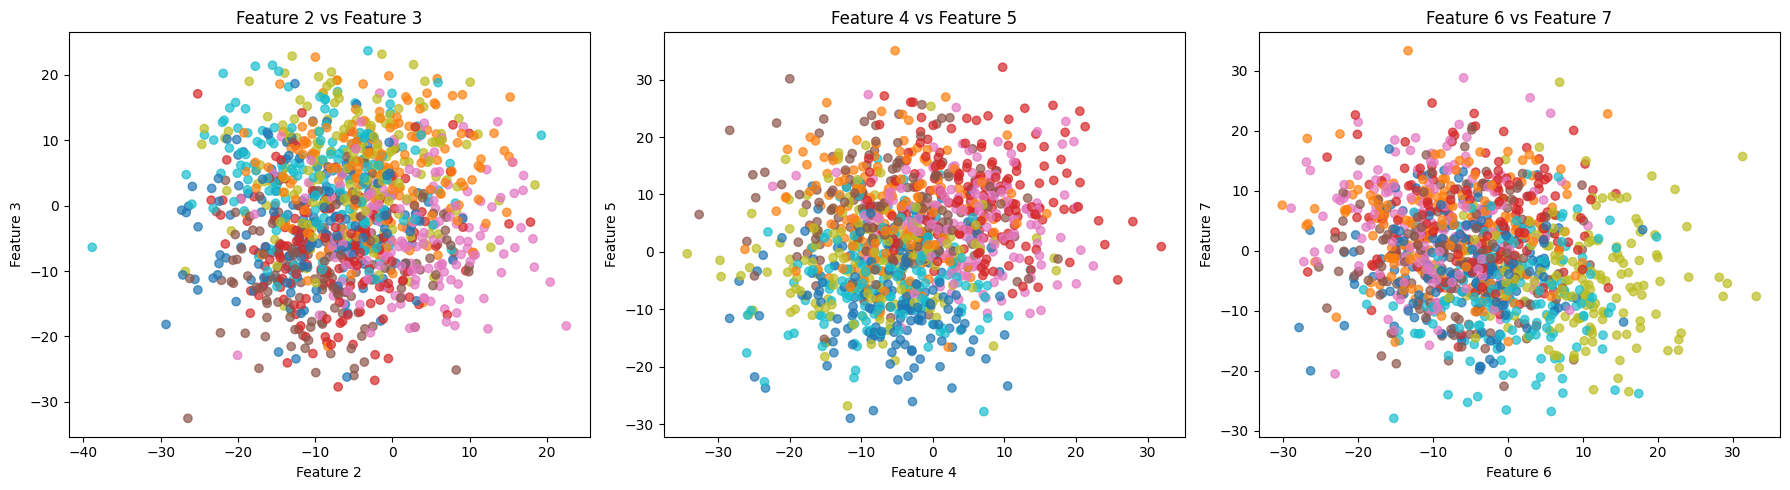

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

feature_pairs = [(2, 3), (4, 5), (6, 7)]

for ax, (i, j) in zip(axes, feature_pairs):
    ax.scatter(
        X[:, i],
        X[:, j],
        c=y,
        cmap="tab10",
        alpha=0.7
    )

    ax.set_xlabel(f"Feature {i}")
    ax.set_ylabel(f"Feature {j}")
    ax.set_title(f"Feature {i} vs Feature {j}")

plt.tight_layout()
plt.show()

## (2) Çok sınıflı sınıflandırma probleminin hedefini kodlama

👉 Şu an için hedef `y`, giriş verisinin ait olduğu kategoriyi temsil eden **tamsayılar listesidir**. Şöyle görünür:  
`[3, 2, 2, 3, 0, 5, 1, 1, 0, 5, ...]`  
(bu örnekte 0’dan 6’ya kadar **7 kategori** vardır).

🧑🏻‍🏫 Ancak **Tensorflow/Keras’ta kategorik problemler için hedef/çıktı (`target/output`) aşağıdaki şekilde encode edilmelidir**:

```
[
[0, 0, 0, 1, 0, 0, 0], 
[0, 0, 1, 0, 0, 0, 0], 
[0, 0, 1, 0, 0, 0, 0], 
[1, 0, 0, 0, 0, 0, 0], 
[0, 0, 0, 0, 0, 1, 0], 
[0, 1, 0, 0, 0, 0, 0],
[0, 1, 0, 0, 0, 0, 0],
[1, 0, 0, 0, 0, 0, 0],
[0, 0, 0, 0, 0, 0, 1],
...
]
```


Burada:
- satır sayısı, **gözlem sayısına** eşittir  
- sütun sayısı, **farklı kategori sayısına** eşittir  

👉 Her sütun bir **kategoriyi** temsil eder.  

👉 Her satır bir **hedefi** temsil eder; `1` değeri, giriş verisinin ait olduğu kategoriyi gösterir.  

Bir satırı, olasılık vektörü olarak düşünebilirsiniz.

```
Örnek:
| Cat 0 | Cat 1 | Cat 2 | Cat 3 | Cat 4 | Cat 5 | Cat 6 |
|-------|-------|-------|-------|-------|-------|-------|
| 0     | 0     | 0     | 1     | 0     | 0     | 0     |

Bu, ilgili satırın %100 olasılıkla Cat 3’e ait olduğu anlamına gelir.
Cat 3
```


---

💡 `y`’yi kategorik hale dönüştürmek için **Tensorflow/Keras içindeki `to_categorical`** fonksiyonunu kullanın.

<details>
    <summary><i>Tensorflow/Keras’taki <code>to_categorical</code> ile Scikit-Learn’deki <code>OneHotEncoder</code> arasında bir benzerlik var mı?</i></summary>

Evet! **`to_categorical`**, Sklearn’deki `OneHotEncoder` gibi çalışır;  
ancak burada bir **kategorik feature** değil, **kategorik target (hedef)** encode edilir.

</details>

---

❓ **Kategorik hedefin kodlanması**:  `y` yazdırın, ardından *to_categorical* işlevini *`y`* üzerinde uygulayın ve *y'nin kategorize edilmiş halini* `y_cat` adlı bir değişkene kaydedin. ❓

In [4]:
from tensorflow.keras.utils import to_categorical

print("Orijinal y:")
print(y)

y_cat = to_categorical(y, num_classes=7)

print("\nKategorik y:")
print(y_cat)

print("\nOrijinal y shape:", y.shape)
print("Kategorik y shape:", y_cat.shape)

2026-11-24 22:07:53.109729: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-24 22:07:53.110509: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 22:07:53.112825: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 22:07:53.120063: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-24 22:07:53.133687: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

Orijinal y:
[2 2 5 ... 1 3 0]

Kategorik y:
[[0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 ...
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]]

Orijinal y shape: (1200,)
Kategorik y shape: (1200, 7)


## (3) Çok Sınıflı Sınıflandırma Görevi için Sinir Ağı

❓ **Hold-out yöntemi**: Veri kümesi $X$ ve $y_{cat}$ 'i _train_ ve _test_ kümelerine ayırın (boyut: 70/30%)

Not: Değişkenleri `X_train`, `X_test`, `y_train` ve `y_test` olarak adlandırın ❓

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_cat,
    test_size=0.30,
    random_state=1,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (840, 8)
X_test: (360, 8)
y_train: (840, 7)
y_test: (360, 7)


Derin Öğrenmede, herhangi bir Makine Öğrenimi algoritmasında olduğu gibi, sayısal özellikleriniz ölçeklendirilmelidir.

❓ **Ölçeklendirme**: Eğitim kümesine bir Sklearn [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) uydurun ve hem eğitim kümenizi hem de test kümenizi dönüştürün ❓

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train mean:", X_train.mean(axis=0).round(4))
print("Train std:", X_train.std(axis=0).round(4))

Train mean: [-0.  0.  0. -0.  0. -0. -0.  0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1.]


❓ **Modeli başlatma**: Aşağıdaki işlevi tamamlayarak aşağıdaki özelliklere sahip bir model oluşturun/başlatın:
- İlk katman:
   - 50 nöron
   - `relu` aktivasyonu
   - Doğru giriş boyutu
- Çıkış katmanı:
   - Çok sınıflı sınıflandırma görevi için tasarlanmış
   - Her sınıfa ait olma olasılıklarını çıktı olarak veren ❓

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

def initialize_model():

    # 1 - Model mimarisi
    model = Sequential([
        Input(shape=(8,)),
        Dense(50, activation='relu'),
        Dense(7, activation='softmax')
    ])

    # 2 - Optimizasyon yöntemi
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return model

model = initialize_model()

2026-11-24 22:09:29.229222: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-24 22:09:29.229617: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


❓  Modelde kaç parametre (diğer adıyla ağırlık) vardır? ❓

In [8]:
model.summary()

print("Toplam parametre:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │           450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           357 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 807 (3.15 KB)

 Trainable params: 807 (3.15 KB)

 Non-trainable params: 0 (0.00 B)

Toplam parametre: 807


❓ **Modeli uydurma**: Modelinizi 50 dönemlik tren verilerine uydurun ve geçmişi çizin ❓

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3289 - loss: 1.8102 - val_accuracy: 0.3333 - val_loss: 1.7738
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4271 - loss: 1.6404 - val_accuracy: 0.4167 - val_loss: 1.6440
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5030 - loss: 1.4987 - val_accuracy: 0.4821 - val_loss: 1.5346
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5670 - loss: 1.3754 - val_accuracy: 0.5119 - val_loss: 1.4425
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6235 - loss: 1.2703 - val_accuracy: 0.5476 - val_loss: 1.3604
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6429 - loss: 1.1786 - val_accuracy: 0.5833 - val_loss: 1.2905
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6637 - loss: 1.0995 - val_accuracy: 0.5893 - val_loss: 1.2338
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6845 - loss: 1.0349 - val_accuracy: 0.5833 - val_loss

❓ **Değerlendirme**:  Modelinizi test setinde değerlendirin ve doğruluğu yazdırın ❓

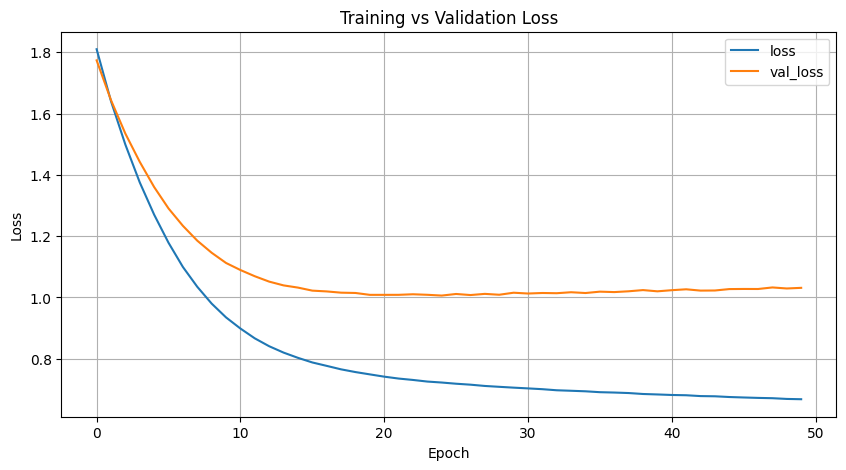

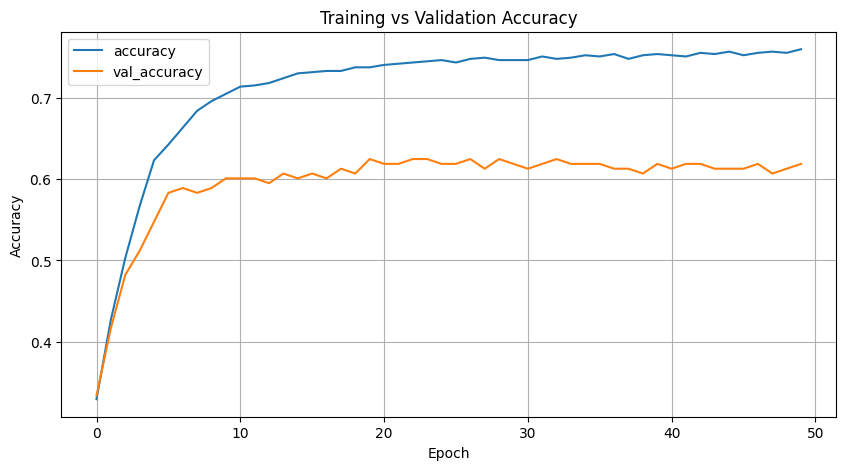

In [10]:
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df[['loss', 'val_loss']].plot(
    figsize=(10, 5),
    title="Training vs Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

history_df[['accuracy', 'val_accuracy']].plot(
    figsize=(10, 5),
    title="Training vs Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

❓ 🤔 Bu iyi bir puan mı? Bunu bir tür karşılaştırma değeriyle karşılaştırmalısınız. Bu durumda, rastgele bir tahminle ne kadar puan elde edilebilir? Bu temel puanı `accuracy_baseline` değişkeninde saklayın. ❓

(Bunun için kod yazmanıza gerek yok, sadece veri setimizin nasıl oluşturulduğunu düşünün.)

In [13]:
accuracy_baseline = 1 / 7

print(accuracy_baseline)

0.14285714285714285


🧪 **Kodunu Test Et**

In [14]:
from nbresult import ChallengeResult
result = ChallengeResult('baseline',
                         accuracy=accuracy_baseline)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S18D2-S-Data-multiclass-classification/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 1 item

test_baseline.py::TestBaseline::test_accuracy PASSED                     [100%]

============================== 1 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/baseline.pickle

git commit -m 'Completed baseline step'

git push origin master



❗ 👀 Bekle ... Kayıp grafiğine daha yakından bakarsan, 50 dönemden sonra da kayıp hala azalmaya devam ediyor gibi görünüyor. Neden bu kadar erken durduruyorsun ❓❗

❓ Modeli yeniden başlatıp bu sefer 1000 dönemle tekrar çalıştıralım ve geçmişi tekrar grafiğe çizelim. ❓

In [17]:
model_1000 = initialize_model()

history_1000 = model_1000.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_split=0.2,
    verbose=2
)

plt.figure(figsize=(10, 5))
plt.plot(history_1000.history['loss'], label='Train Loss')
plt.plot(history_1000.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss - 1000 Epochs")
plt.legend()
plt.grid()
plt.show()

Epoch 1/1000
6/6 - 1s - 96ms/step - accuracy: 0.1533 - loss: 2.0516 - val_accuracy: 0.1667 - val_loss: 2.0164
Epoch 2/1000
6/6 - 0s - 10ms/step - accuracy: 0.1979 - loss: 1.9771 - val_accuracy: 0.1964 - val_loss: 1.9515
Epoch 3/1000
6/6 - 0s - 10ms/step - accuracy: 0.2440 - loss: 1.9052 - val_accuracy: 0.2560 - val_loss: 1.8916
Epoch 4/1000
6/6 - 0s - 10ms/step - accuracy: 0.3051 - loss: 1.8396 - val_accuracy: 0.3095 - val_loss: 1.8355
Epoch 5/1000
6/6 - 0s - 10ms/step - accuracy: 0.3571 - loss: 1.7780 - val_accuracy: 0.3452 - val_loss: 1.7824
Epoch 6/1000
6/6 - 0s - 10ms/step - accuracy: 0.4048 - loss: 1.7208 - val_accuracy: 0.3750 - val_loss: 1.7321
Epoch 7/1000
6/6 - 0s - 10ms/step - accuracy: 0.4301 - loss: 1.6659 - val_accuracy: 0.3929 - val_loss: 1.6855
Epoch 8/1000
6/6 - 0s - 10ms/step - accuracy: 0.4435 - loss: 1.6142 - val_accuracy: 0.4048 - val_loss: 1.6411
Epoch 9/1000
6/6 - 0s - 10ms/step - accuracy: 0.4747 - loss: 1.5653 - val_accuracy: 0.4226 - val_loss: 1.5991
Epoch 10/1

KeyboardInterrupt: 

❓ **Bir modeli daha uzun süre eğitirken...** ❓
- Yeni kayıp hakkında ne söyleyebilirsiniz?
- Modelinizi test setinde bir kez daha değerlendirin ve doğruluğu yazdırın.

In [19]:
test_loss_1000, test_accuracy_1000 = model_1000.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss_1000:.4f}")
print(f"Test Accuracy: {test_accuracy_1000:.4f}")
print(f"Test Accuracy (%): {test_accuracy_1000 * 100:.2f}")

print("\n50 vs 1000 Epoch Comparison")
print("50 Epoch Accuracy:", test_accuracy)
print("1000 Epoch Accuracy:", test_accuracy_1000)

Test Loss: 1.0255
Test Accuracy: 0.6639
Test Accuracy (%): 66.39

50 vs 1000 Epoch Comparison


NameError: name 'test_accuracy' is not defined

* 😁 Tren setinde hesaplanan kayıp, 50 epok ile karşılaştırıldığında 1000 epok ile daha küçük görünüyor.
* 😟 Anc ak test setindeki doğruluk, 50 epok ile karşılaştırıldığında 1000 epok ile daha kötü...

❓ Bu fenomene ne denir? ❓

> Bu fenomene Overfitting (aşırı uyum) denir. Model, eğitim verilerini gereğinden fazla öğrenerek verilerdeki gürültüyü ve detayları ezberlemeye başlar. Eğitim kaybı azalırken test performansı kötüleşir ve modelin genelleme yeteneği düşer.

---

🤔 Bunun olmasını önlemek için ne yapmalıyız? 

<details>
    <summary><i>Olası seçenekler</i></summary>
    

⚠️ Sinir ağlarında aşırı uyumun olmasını önlemek için, örneğin şunları yapabiliriz:
1. Sinir ağının gürültülü veri noktalarından çok fazla öğrenmesini önlemek için ***makul sayıda dönem*** seçin
2. ***Erken Durdurma*** kriteri, yani _.fit()_ 📆 cf. ***Derin Öğrenme > Optimize Ediciler, Kayıp, Uydurma***

</details>    

---


❓ Test kaybının pratikte ne zaman tekrar artmaya başladığını görsel olarak kontrol edelim.  Aşağıdaki komutu çalıştırın ve geçmişi çizin❓

In [20]:
model = initialize_model()

history = model.fit(X_train,
                    y_train,
                    validation_data=(X_test, y_test),
                    epochs=500,
                    batch_size=16,
                    verbose=0)
plot_history(history)

KeyboardInterrupt: 

😱 Ama durun... test setini kullanırsak hile yapmış olmaz mıyız? Evet, oluruz. Ama yine sabırlı olun. ***Derin Öğrenme - Optimize Ediciler, Kayıp, Uydurma*** bölümünde, bunu önlemek için ***Doğrulama Seti*** adını verdiğimiz şeyi kullanacağız!

🧘🏻‍♀️ Şimdilik, sonraki sorulara geçelim!

❓ **Ağı değerlendirme**: <span style="color:blue">eğitim seti</span> ve <span style="color:orange">test seti</span> üzerindeki kayıp ve doğruluk değerlerini grafik olarak gösterin. Bu konuda ne söyleyebilirsiniz? ❓ 

In [21]:
def plot_loss_accuracy(history):
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='best')
    plt.show()

    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Test'], loc='best')
    plt.show()

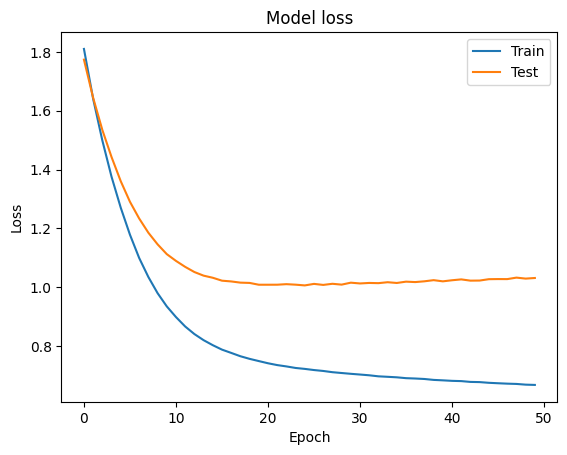

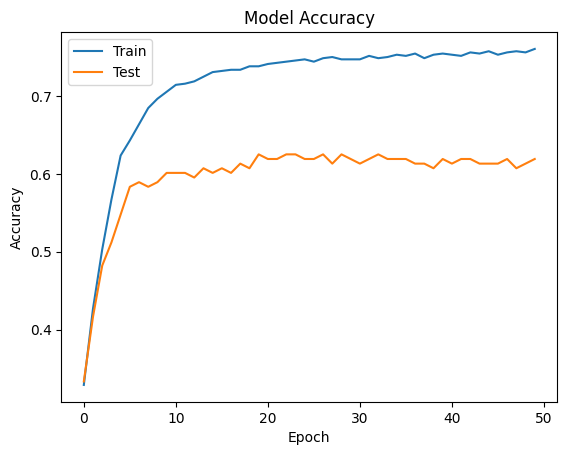

Best Epoch: 25
Minimum Test Loss: 1.0062391757965088
Final Train Loss: 0.667961835861206
Final Test Loss: 1.0314422845840454
Final Train Accuracy: 0.7604166865348816
Final Test Accuracy: 0.6190476417541504


In [22]:
plot_loss_accuracy(history)

best_epoch = np.argmin(history.history['val_loss']) + 1

print("Best Epoch:", best_epoch)
print("Minimum Test Loss:", min(history.history['val_loss']))
print("Final Train Loss:", history.history['loss'][-1])
print("Final Test Loss:", history.history['val_loss'][-1])
print("Final Train Accuracy:", history.history['accuracy'][-1])
print("Final Test Accuracy:", history.history['val_accuracy'][-1])

🤔 Derin Öğrenme modelimiz neden bu kadar kolay aşırı uyum sağlıyor?

😳 Düşünün, sinir ağımız sadece 8 özellik içeren bir veri kümesinden basit bir sınıflandırma görevi için ~800 parametre öğrenmek zorunda! Üstelik, uyum sağlamak için toplamda sadece ~800 veri noktamız var! Model, eğitim kümesindeki her noktanın tam sınıfını neredeyse “öğrenebilir”. 

Buna karşılık, basit bir Lojistik Regresyon, bu blob veri kümesinin kalıplarını yakalamak için sadece 9 parametreyi öğrenmek zorunda kalırdı! 

😏 Derin öğrenme etkileyici bir kavramdır, ancak basit makine öğrenimi görevleri için açıkça aşırı ve gereksiz bir seçenek olabilir!

⭐️ Aşağıdakiler için son derece yararlı olacaktır:
- 📸 Görüntü işleme
- 💹 Zaman serileri
- 🗣 Doğal dil işleme

---

🏁 Tebrikler!

💾 Not defterinizi `git add/commit/push` yapmayı unutmayın...

🚀 ... ve bir sonraki göreve geçin!